<img src="https://complexsystemsintelligence.github.io/biztonsagkritikus-rendszerek/gyakorlat/assets/logo/pe-cimer-nevjel-fekvo-kek.png" alt="Pannon Egyetem – University of Pannonia" height="56">

[Megnyitás a Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/biztonsagkritikus-rendszerek/blob/main/gyakorlat/notebookok/11_sil.ipynb) · *Biztonságkritikus rendszerek – gyakorlati útmutató* · © 2026 Abonyi János, Pannon Egyetem · kód: MIT, szöveg: CC BY-NC-SA 4.0

# 11. gyakorlat – PFD és SIL-igazolás

A notebook a könyv 13. fejezetének ReaktorVéd-igazolását végzi el: az IEC 61508-6 egyszerűsített képletei, részleges löketpróba, nem tökéletes proof teszt, érzékenységvizsgálat (tornádó), végül Monte Carlo-bizonytalanság a PFD-re.

**Tanulási eredmények:** PFD<sub>avg</sub> számítása 1oo1, 1oo2 és 2oo3 alrendszerekre; a tesztelési stratégia hatásának értékelése; az eredmény bizonytalanságának becslése.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
PE = {"kek": "#285780", "sotet": "#1B3A57", "kiemel": "#E07B39", "zold": "#3E8E63", "piros": "#B83A3A", "lila": "#7A5C99", "szurke": "#6B7280"}
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.grid": True, "grid.color": "#e6e9ee", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=list(PE.values())), "axes.formatter.use_locale": False})
def hu(x, sig=3):
    """Szám magyar formátumban (tizedesvessző, normálalak)."""
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    if -2 <= e < 5: return f"{x:.{max(0, sig-1-e)}f}".replace(".", ",")
    return f"{x/10**e:.{sig-1}f}".replace(".", ",") + f"·10^{e}"


In [2]:
T1, MTTR, TM = 8760.0, 8.0, 87600.0
def ido(lDU, lDD, ptc=1.0, Tp=None, dcp=0.0, T1=T1):
    lD = lDU + lDD
    if Tp is None:
        a1 = ptc*(T1/2+MTTR) + (1-ptc)*TM/2; a2 = ptc*(T1/3+MTTR) + (1-ptc)*TM/3
    else:
        a1 = (1-dcp)*(T1/2+MTTR) + dcp*(Tp/2+MTTR); a2 = (1-dcp)*(T1/3+MTTR) + dcp*(Tp/3+MTTR)
    return lDU/lD*a1 + lDD/lD*MTTR, lDU/lD*a2 + lDD/lD*MTTR, a1
def pfd(arch, lDU, lDD, beta=0.0, betaD=0.0, **kw):
    tCE, tGE, a1 = ido(lDU, lDD, **kw); lf = (1-betaD)*lDD + (1-beta)*lDU
    ccf = betaD*lDD*MTTR + beta*lDU*a1
    if arch == "1oo1": return (lDU+lDD)*tCE
    if arch == "1oo2": return 2*lf**2*tCE*tGE + ccf
    if arch == "2oo3": return 6*lf**2*tCE*tGE + ccf
def sif(**kw):
    s = pfd("1oo2", 4e-7, 6e-7, 0.05, 0.025, T1=kw.get("T1", T1))
    v = pfd("1oo2", 2.5e-6*kw.get("vfak", 1), 0.0, kw.get("vbeta", 0.10), 0.05,
            ptc=kw.get("ptc", 1.0), Tp=kw.get("Tp"), dcp=kw.get("dcp", 0.0), T1=kw.get("T1", T1))
    return s + 5e-5 + v, s, v
tot, s, v = sif()
print(f"távadók {hu(s)}, logika 5,0·10^-5, szelepek {hu(v)}  ->  PFD = {hu(tot, 4)}, RRF = {1/tot:.0f}")
print("PST havonta (DC 60 %):", hu(sif(Tp=730, dcp=0.6)[0], 4))
print("PTC 90 %:             ", hu(sif(ptc=0.9)[0], 4))

távadók 9,17·10^-5, logika 5,0·10^-5, szelepek 1,23·10^-3  ->  PFD = 1,369·10^-3, RRF = 731
PST havonta (DC 60 %): 6,630·10^-4
PTC 90 %:              2,693·10^-3


## Tornádódiagram

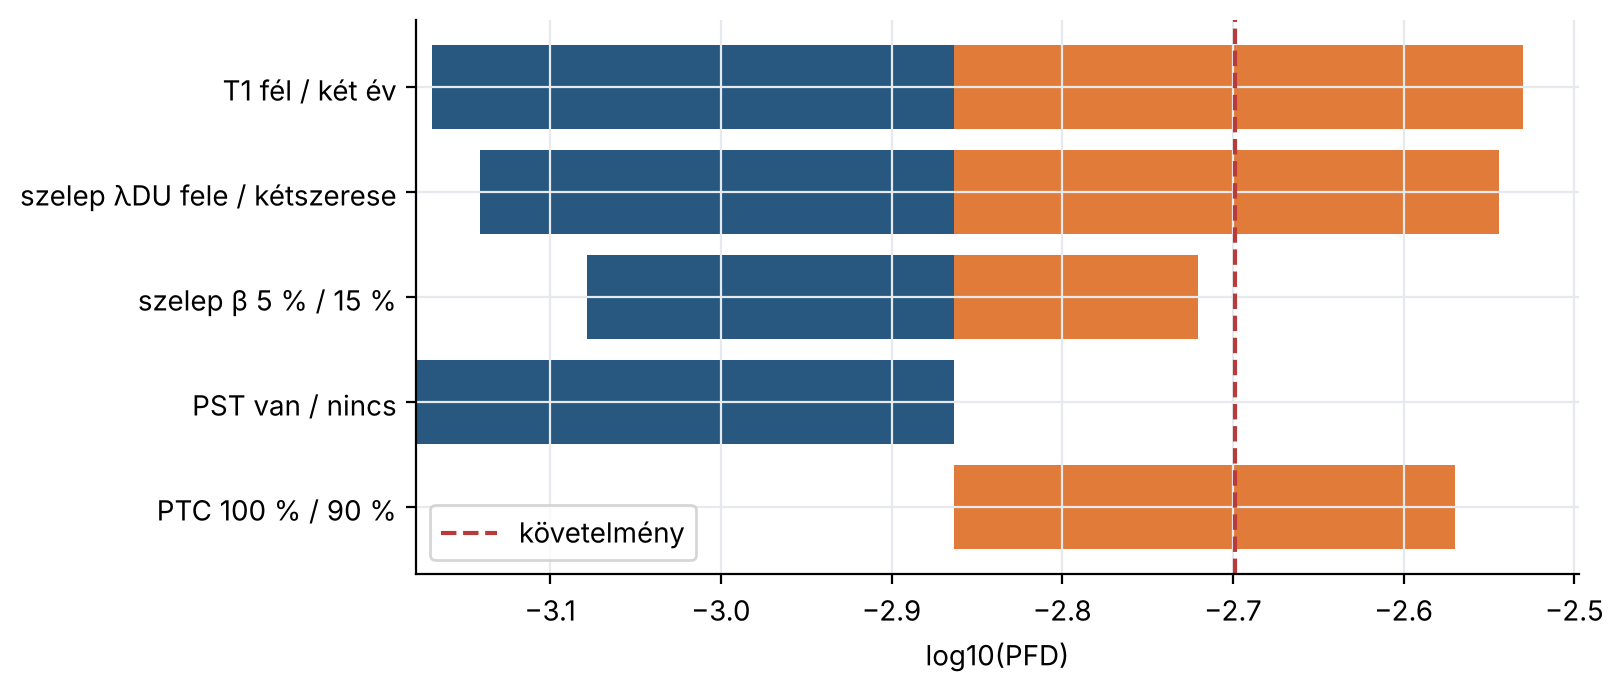

In [3]:
esetek = [("T1 fél / két év", sif(T1=4380)[0], sif(T1=17520)[0]),
          ("szelep λDU fele / kétszerese", sif(vfak=0.5)[0], sif(vfak=2)[0]),
          ("PTC 100 % / 90 %", tot, sif(ptc=0.9)[0]),
          ("szelep β 5 % / 15 %", sif(vbeta=0.05)[0], sif(vbeta=0.15)[0]),
          ("PST van / nincs", sif(Tp=730, dcp=0.6)[0], tot)]
esetek.sort(key=lambda e: e[2]/e[1])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (n, lo, hi) in enumerate(esetek):
    ax.barh(i, np.log10(tot) - np.log10(lo), left=np.log10(lo), color=PE["kek"])
    ax.barh(i, np.log10(hi) - np.log10(tot), left=np.log10(tot), color=PE["kiemel"])
ax.axvline(np.log10(2e-3), color=PE["piros"], ls="--", label="követelmény")
ax.set_yticks(range(len(esetek))); ax.set_yticklabels([e[0] for e in esetek]); ax.set_xlabel("log10(PFD)"); ax.legend(); plt.show()

## Monte Carlo: mennyire biztos a SIL 2?

A meghibásodási ráták és a β-tényezők bizonytalanok. Lognormális eloszlást feltételezünk (EF = 3 a rátákra, EF = 2 a β-kra), mediánként a pontbecsléssel.

In [4]:
rng = np.random.default_rng(3); N = 50000
def ln(m, ef, n): return m*np.exp(np.log(ef)/1.645*rng.standard_normal(n))
eredm = []
for lt, lv, bt, bv in zip(ln(4e-7, 3, N), ln(2.5e-6, 3, N), np.minimum(ln(0.05, 2, N), 0.5), np.minimum(ln(0.10, 2, N), 0.5)):
    s_ = pfd("1oo2", lt, 1.5*lt, bt, bt/2); v_ = pfd("1oo2", lv, 0.0, bv, bv/2)
    eredm.append(s_ + 5e-5 + v_)
eredm = np.array(eredm)
print("medián:", hu(np.median(eredm)), " 90 %-os intervallum:", hu(np.percentile(eredm, 5)), "–", hu(np.percentile(eredm, 95)))
print("P(PFD > 2·10^-3) =", round((eredm > 2e-3).mean(), 3))

medián: 1,44·10^-3  90 %-os intervallum: 4,85·10^-4 – 5,21·10^-3
P(PFD > 2·10^-3) = 0.331


**Értelmezés.** A pontbecslés teljesíti a követelményt, de a bizonytalanság figyelembevételével jelentős (az eredmény szerint nagyjából egyharmad) annak a valószínűsége, hogy a valódi PFD a határ fölött van. Ez erős érv a részleges löketpróba mellett, és az IEC 61508 2H útjának bizonytalanságkezelési követelményét is szemlélteti.

**1. feladat.** Ismételd meg a Monte Carlo-elemzést havi részleges löketpróbával! Hogyan változik a túllépés valószínűsége?

**2. feladat.** Számold ki a 2oo3 távadó-architektúra PFD-jét és téves leállási gyakoriságát, és hasonlítsd össze az 1oo2-vel!

## Mintaprompt

*„Az alábbi biztonsági funkció PFD-jét az IEC 61508-6 egyszerűsített képleteivel számoltam: … Ellenőrizd, hogy a képletek feltevései (λT ≪ 1, egyidejű tesztelés, tökéletes próba) teljesülnek-e, és sorold fel, melyik feltevés sérülése rontaná leginkább az eredményt! Szabványpontra csak akkor hivatkozz, ha biztos vagy benne.”*